# 02 - Diabetes risk modelling (8-feature BRFSS 2024 dataset)
Run the cells **in order** with Shift + Enter (or Kernel -> Restart & Run All).

## Step 1. DATA COLLECTION - CDC BRFSS 2024 dataset (8 features + Outcome)

In [1]:
import pandas as pd, numpy as np, joblib, json, time
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

df = pd.read_csv("../data/brfss2024_8features.csv")
print(df.shape)
df.head()

(441934, 9)


,GENHLTH,DIFFWALK,_AGEG5YR,_BMI5,_MICHD,PHYSHLTH,EXERANY2,INCOME3,Outcome
0,3.0,0.0,12.0,22.49,0.0,2.0,1.0,NaN,0
1,1.0,0.0,13.0,25.83,1.0,0.0,1.0,11.0,0
2,2.0,0.0,8.0,22.53,0.0,30.0,1.0,NaN,0
3,1.0,0.0,13.0,25.09,0.0,0.0,1.0,6.0,0
4,3.0,1.0,6.0,19.77,0.0,0.0,0.0,3.0,0


## Step 2. CLEANING - check the cleaned data
Cleaning rules already applied to the raw survey file: keep only clear yes/no diabetes answers; 7 / 9 / 77 / 99 codes -> blank; yes/no answers -> 1/0; 88 days -> 0; BMI divided by 100; the original diabetes column removed (prevents leakage).

In [2]:
print(df["Outcome"].value_counts())
print(df["Outcome"].value_counts(normalize=True).round(3))
print()
print("Missing values (%):")
print((df.isna().mean() * 100).round(1))
df.describe().T[["min", "max", "mean"]].round(2)

Outcome
0    376125
1     65809
Name: count, dtype: int64
Outcome
0    0.851
1    0.149
Name: proportion, dtype: float64

Missing values (%):
GENHLTH      0.3
DIFFWALK     4.5
_AGEG5YR     1.8
_BMI5        9.4
_MICHD       1.1
PHYSHLTH     2.4
EXERANY2     0.3
INCOME3     19.0
Outcome      0.0
dtype: float64


,min,max,mean
GENHLTH,1.0,5.00,2.63
DIFFWALK,0.0,1.00,0.16
_AGEG5YR,1.0,13.00,7.65
_BMI5,12.0,99.84,28.48
_MICHD,0.0,1.00,0.09
PHYSHLTH,0.0,30.00,4.55
EXERANY2,0.0,1.00,0.77
INCOME3,1.0,11.00,7.02
Outcome,0.0,1.00,0.15


## Step 3. EDA - age, BMI and general health (charts saved into the reports folder)

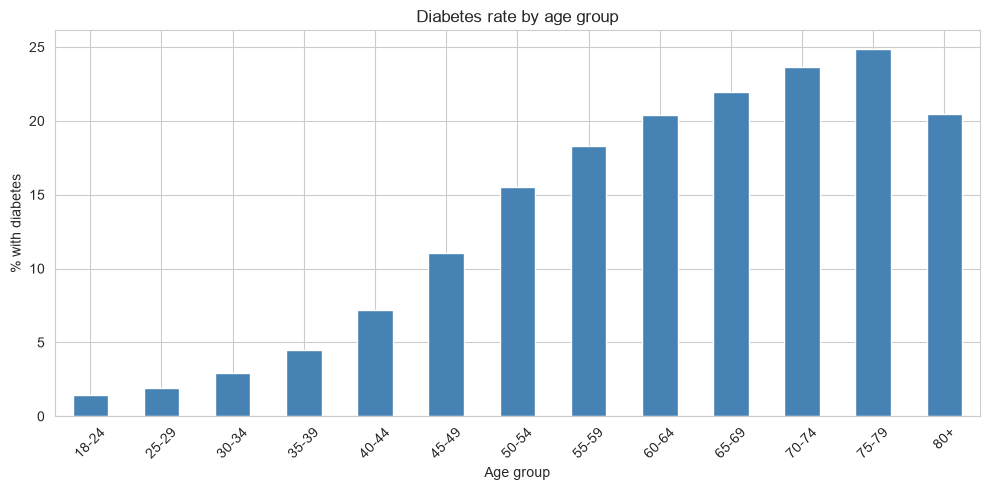

In [3]:
age_labels = {1:"18-24", 2:"25-29", 3:"30-34", 4:"35-39", 5:"40-44", 6:"45-49",
              7:"50-54", 8:"55-59", 9:"60-64", 10:"65-69", 11:"70-74", 12:"75-79", 13:"80+"}

rate = df.groupby("_AGEG5YR")["Outcome"].mean() * 100
rate.index = [age_labels[int(i)] for i in rate.index]

plt.figure(figsize=(10, 5))
rate.plot(kind="bar", color="steelblue")
plt.title("Diabetes rate by age group")
plt.ylabel("% with diabetes"); plt.xlabel("Age group")
plt.xticks(rotation=45); plt.tight_layout()
plt.savefig("../reports/diabetes_by_age.png", dpi=150)
plt.show()

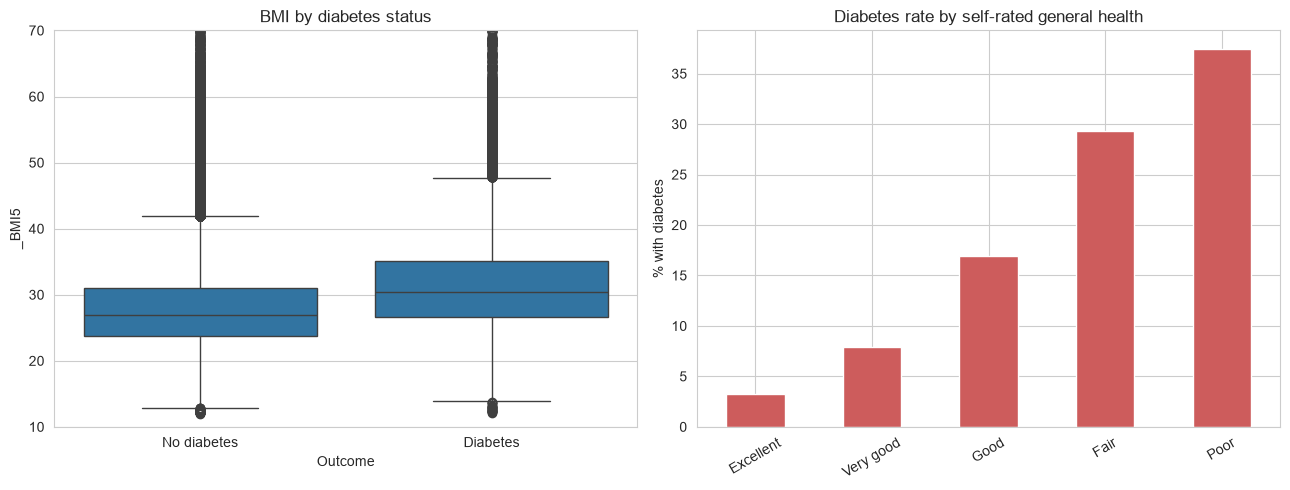

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x="Outcome", y="_BMI5", ax=ax[0])
ax[0].set_title("BMI by diabetes status")
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["No diabetes", "Diabetes"])
ax[0].set_ylim(10, 70)

health = df.groupby("GENHLTH")["Outcome"].mean() * 100
health.index = ["Excellent", "Very good", "Good", "Fair", "Poor"]
health.plot(kind="bar", ax=ax[1], color="indianred")
ax[1].set_title("Diabetes rate by self-rated general health")
ax[1].set_ylabel("% with diabetes"); ax[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("../reports/bmi_and_health.png", dpi=150)
plt.show()

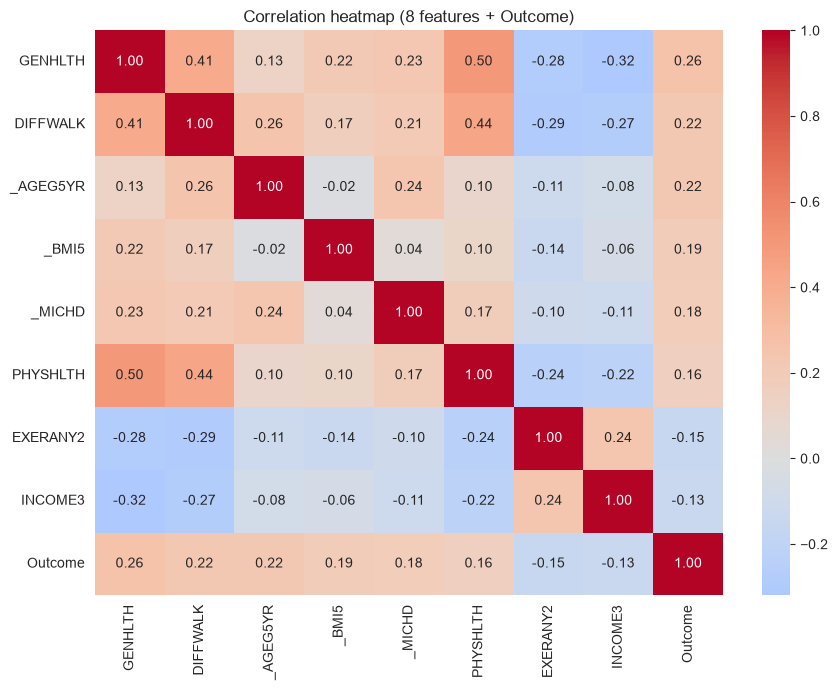

In [5]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap (8 features + Outcome)")
plt.tight_layout()
plt.savefig("../reports/correlation_heatmap.png", dpi=150)
plt.show()

## Step 4. Split the data (train 80% / test 20%) - done before any preprocessing
The split happens **before** any filling of blanks or scaling, so the test people stay completely unseen.

In [6]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="Outcome")
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Diabetes rate  train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))

Train: (353547, 8)  Test: (88387, 8)
Diabetes rate  train: 0.149  test: 0.149


## Step 5. MODEL TRAINING - LR, DT, RF, XGBoost
Models are trained **without** class weights, so the predicted percentages are realistic
(the average predicted risk should be close to the real 14.9%). Recall and precision are
reported at a screening threshold of 0.15 (flag anyone whose risk is 15% or more).

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score, brier_score_loss

THRESHOLD = 0.15

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=50,
                                         n_jobs=-1, random_state=42))]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, random_state=42))]),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                             n_jobs=-1, random_state=42, eval_metric="logloss"),
}

results, trained = [], {}
for name, m in models.items():
    start = time.time()
    m.fit(X_train, y_train)
    prob = m.predict_proba(X_test)[:, 1]
    flag = (prob >= THRESHOLD).astype(int)
    trained[name] = m
    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Recall@0.15": recall_score(y_test, flag),
        "Precision@0.15": precision_score(y_test, flag),
        "F1@0.15": f1_score(y_test, flag),
        "Brier": brier_score_loss(y_test, prob),
        "Avg predicted risk": prob.mean(),
    })
    print(f"{name} done in {time.time() - start:.0f} seconds")

comparison = pd.DataFrame(results).round(3).sort_values("ROC-AUC", ascending=False)
comparison.to_csv("../reports/model_comparison.csv", index=False)
print()
print("Real diabetes rate in test set:", round(y_test.mean(), 3))
comparison

Logistic Regression done in 1 seconds
Random Forest done in 37 seconds
Decision Tree done in 2 seconds
XGBoost done in 13 seconds

Real diabetes rate in test set: 0.149


,Model,ROC-AUC,Recall@0.15,Precision@0.15,F1@0.15,Brier,Avg predicted risk
3,XGBoost,0.801,0.780,0.295,0.428,0.107,0.150
1,Random Forest,0.799,0.790,0.288,0.423,0.107,0.150
0,Logistic Regression,0.791,0.729,0.303,0.428,0.109,0.149
2,Decision Tree,0.786,0.746,0.292,0.419,0.109,0.150


## Step 6. EVALUATION - compare the models
The table above already compares the four models. Here we add the ROC curves (higher curve = better)
and the confusion matrix of each model at the 0.15 screening threshold.

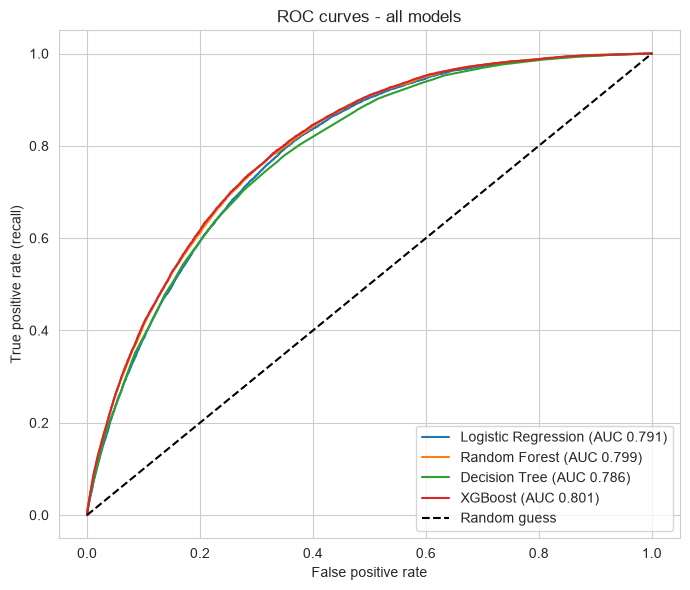

In [8]:
from sklearn.metrics import roc_curve, confusion_matrix

plt.figure(figsize=(7, 6))
for name, m in trained.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curves - all models"); plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../reports/roc_curves.png", dpi=150)
plt.show()

In [9]:
rows = []
for name, m in trained.items():
    flag = (m.predict_proba(X_test)[:, 1] >= THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, flag).ravel()
    rows.append({"Model": name, "Caught (TP)": tp, "Missed (FN)": fn,
                 "False alarms (FP)": fp, "Correct no-diabetes (TN)": tn})
pd.DataFrame(rows)

,Model,Caught (TP),Missed (FN),False alarms (FP),Correct no-diabetes (TN)
0,Logistic Regression,9590,3572,22073,53152
1,Random Forest,10403,2759,25678,49547
2,Decision Tree,9815,3347,23819,51406
3,XGBoost,10272,2890,24573,50652


## Step 7. SELECTION - choose the final model
XGBoost is selected because (1) its ROC-AUC is equal or almost equal to the best model,
(2) it handles blank values itself, and (3) it works with SHAP, so the dashboard can explain every prediction.
Then we check the percentages, choose the screening threshold and define the Low / Moderate / High risk levels.

In [10]:
final_model = trained["XGBoost"]
prob = final_model.predict_proba(X_test)[:, 1]

best_auc = comparison["ROC-AUC"].max()
xgb_auc = roc_auc_score(y_test, prob)
print("Best ROC-AUC among models:", round(best_auc, 3), " XGBoost:", round(xgb_auc, 3))
print()
print("Average predicted risk:", round(prob.mean(), 3))
print("Real diabetes rate:    ", round(y_test.mean(), 3))

rows = []
for t in [0.10, 0.12, 0.15, 0.20, 0.25, 0.30]:
    p = (prob >= t).astype(int)
    rows.append({"Threshold": t, "Recall": recall_score(y_test, p),
                 "Precision": precision_score(y_test, p),
                 "% of people flagged": p.mean() * 100})
threshold_table = pd.DataFrame(rows).round(3)
threshold_table.to_csv("../reports/threshold_table.csv", index=False)
threshold_table

Best ROC-AUC among models: 0.801  XGBoost: 0.801

Average predicted risk: 0.15
Real diabetes rate:     0.149


,Threshold,Recall,Precision,% of people flagged
0,0.10,0.878,0.256,51.049
1,0.12,0.838,0.273,45.730
2,0.15,0.780,0.295,39.423
3,0.20,0.678,0.332,30.435
4,0.25,0.561,0.368,22.673
5,0.30,0.448,0.406,16.406


In [11]:
LOW_MAX, HIGH_MIN = 0.10, 0.25   # Low < 10%, Moderate 10-25%, High >= 25%

bands = pd.cut(prob, [0, LOW_MAX, HIGH_MIN, 1.0],
               labels=["Low", "Moderate", "High"], include_lowest=True)
band_table = (pd.DataFrame({"Risk level": bands, "Has diabetes": y_test.values})
              .groupby("Risk level", observed=True)["Has diabetes"]
              .agg(People="count", Real_diabetes_rate="mean").round(3))
band_table["Real_diabetes_rate"] = (band_table["Real_diabetes_rate"] * 100).round(1)
band_table.to_csv("../reports/risk_band_table.csv")
band_table

,People,Real_diabetes_rate
Risk level,,
Low,43266,3.7
Moderate,25081,16.6
High,20040,36.8


## Step 8. DEPLOYMENT - save the model for the Streamlit dashboard

In [12]:
joblib.dump(final_model, "../models/xgb_model.pkl")
joblib.dump(list(X.columns), "../models/feature_names.pkl")
with open("../models/settings.json", "w") as f:
    json.dump({"low_max": LOW_MAX, "high_min": HIGH_MIN, "threshold": THRESHOLD}, f)
print("Saved model, feature names and settings in the models folder")

Saved model, feature names and settings in the models folder


## Step 7b. Explain the selected model with SHAP

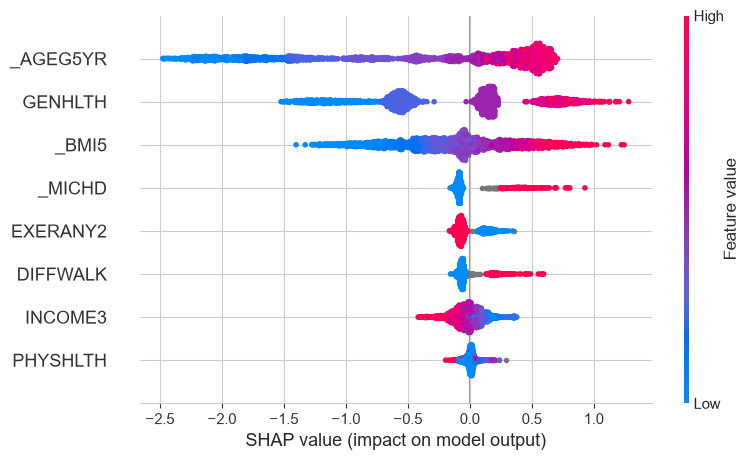

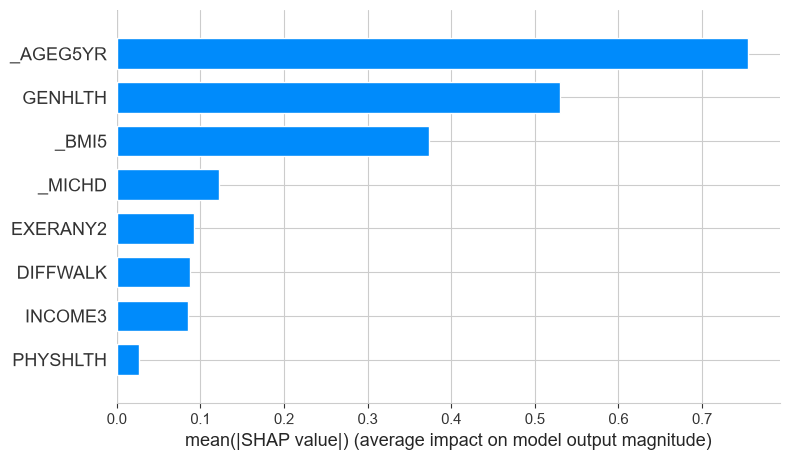

In [13]:
import shap

sample = X_test.sample(3000, random_state=42)
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(sample)

plt.figure()
shap.summary_plot(shap_values, sample, show=False)
plt.tight_layout()
plt.savefig("../reports/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure()
shap.summary_plot(shap_values, sample, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig("../reports/shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()